# Block 5 — Are your tower years normal?

**Question 4:** How far is each tower year's mean temperature and precipitation from the WorldClim 1970–2000 normal (BIO1, BIO12)?

**Hypothesis:** Tower years are on average warmer than the 1970–2000 normal (recent warming), and the warmest deviations occur at the driest towers, because in water-limited ecosystems low precipitation coincides with high radiation and low evaporative cooling.

**Datasets besides FLUXNET:** WorldClim 2.1 (5′ ≈ 9 km, normals 1970–2000) and SoilGrids 2.0 (250 m, static).

Prerequisites (run once, from the project root):
```bash
python3 scripts/block5/02_worldclim.py --student 18
python3 scripts/block5/04_soilgrids.py --student 18
python3 scripts/block5/09_merge.py     --student 18
```

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path("scripts/block5").resolve()))
import os
os.chdir(Path.cwd().parent.parent)  # notebook lives in scripts/block5; run from project root
sys.path.insert(0, str(Path("scripts/block5").resolve()))
from block5_sites import get_my_sites, parse_args, say

MIN_DAYS = 300      # a year with fewer measured days is dropped
FR_HES_FROM = 2001  # FR-Hes 1997-2000 sits inside the 1970-2000 normal period
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sites = get_my_sites("18")
daily = pd.read_csv("data/processed/site_daily.csv", parse_dates=["date"])
static = pd.read_csv("data/processed/site_static.csv")


==> Your towers:
site_id igbp country        lat        lon  first_year  last_year
 FR-Hes  DBF      FR  48.674100    7.06465        1997       2026
 CA-Ca2  ENF      CA  49.870500 -125.29090        2000       2010
 CN-HaM  GRA      CN  37.607433  101.33200        2001       2014
 US-Bi1  CRO      US  38.099200 -121.49930        2016       2024
 AU-Dry  WSA      AU -15.258800  132.37060        2009       2025


## 1. Tower-year aggregation

FLUXNET daily: `TA_F` in °C, `P_F` in mm d⁻¹. A year with fewer than 300 measured days is dropped, because an annual precipitation sum over a partial year is meaningless.

## 2. Data-quality check on precipitation

Before computing anomalies we check whether the FLUXNET `P_F` is measured or fully model-derived, and whether it is physically plausible.

**CN-HaM fails this check:** its `P_F` is identical to the ERA5-derived `P_ERA` on every day, its `P_F_QC` is 0 everywhere (no measured contribution), and the resulting ~3 000 mm yr⁻¹ contradicts both the WorldClim normal (468 mm) and the published climate of the Haibei station on the north-eastern Tibetan Plateau (~500–600 mm yr⁻¹). The JPF product's ERA5 precipitation for this site is unusable, so CN-HaM is **excluded from the precipitation anomaly** but kept for the temperature anomaly (its `TA_F` is 95% measured and matches BIO1 well).

In [2]:
annual = (daily.assign(year=daily["date"].dt.year)
               .groupby(["site_id", "year"])
               .agg(TA_mean=("TA_F", "mean"), P_sum=("P_F", "sum"), n_days=("TA_F", "size"))
               .reset_index())
n_before = len(annual)
annual = annual[annual["n_days"] >= MIN_DAYS].copy()
print(f"{n_before} tower-years before the >= {MIN_DAYS} days filter, {len(annual)} after")

mask = (annual["site_id"] == "FR-Hes") & (annual["year"] < FR_HES_FROM)
if mask.any():
    print(f"Dropping {mask.sum()} FR-Hes years < {FR_HES_FROM} (inside the 1970-2000 normal)")
    annual = annual[~mask]

# CN-HaM precipitation is unusable (see markdown above): flag it, keep temperature
BAD_P_SITES = ["CN-HaM"]
annual["P_ok"] = ~annual["site_id"].isin(BAD_P_SITES)
annual.head()

81 tower-years before the >= 300 days filter, 81 after
Dropping 4 FR-Hes years < 2001 (inside the 1970-2000 normal)


,site_id,year,TA_mean,P_sum,n_days,P_ok
0,AU-Dry,2009,26.788915,848.366,365,True
1,AU-Dry,2010,28.100085,966.398,365,True
2,AU-Dry,2011,25.138742,1332.945,365,True
3,AU-Dry,2012,26.092358,645.785,366,True
4,AU-Dry,2013,27.430036,805.806,365,True


## 3. Anomalies

- `dT` = tower-year mean temperature − BIO1 (K)
- `dP_pct` = tower-year precipitation sum relative to BIO12 (%) — only where `P_ok`

In [3]:
df = annual.merge(static[["site_id", "BIO1", "BIO12", "soil0_30_clay", "soil0_30_sand"]],
                  on="site_id", how="left")
df["dT"] = df["TA_mean"] - df["BIO1"]
df["dP_pct"] = 100 * (df["P_sum"] - df["BIO12"]) / df["BIO12"]
df.loc[~df["P_ok"], "dP_pct"] = float("nan")  # CN-HaM precipitation unusable
df = df.sort_values(["site_id", "year"]).reset_index(drop=True)
df.to_csv("data/processed/block5_anomalies.csv", index=False)

summary = (df.groupby("site_id")
             .agg(n_years=("year", "size"),
                  dT_mean=("dT", "mean"), dT_min=("dT", "min"), dT_max=("dT", "max"),
                  dP_mean=("dP_pct", "mean"), dP_min=("dP_pct", "min"), dP_max=("dP_pct", "max"),
                  clay=("soil0_30_clay", "first"), sand=("soil0_30_sand", "first"))
             .round(2))
summary

,n_years,dT_mean,dT_min,dT_max,dP_mean,dP_min,dP_max,clay,sand
site_id,,,,,,,,,
AU-Dry,17,0.37,-1.64,2.23,-2.11,-56.06,57.00,27.08,63.97
CA-Ca2,11,-0.11,-0.85,1.03,-28.22,-61.25,-9.81,13.38,37.43
CN-HaM,14,-0.32,-0.91,0.07,NaN,NaN,NaN,17.78,43.30
FR-Hes,26,1.34,-0.46,3.75,14.88,-49.19,57.79,26.87,21.95
US-Bi1,9,-0.68,-2.98,0.76,-2.69,-55.58,26.31,29.98,11.07


## 3. Summary number

In [4]:
n_years = len(df)
n_warm = int((df["dT"] > 0).sum())
p_ok = df[df["P_ok"]]
n_drier = int((p_ok["dP_pct"] < 0).sum())
print(f"Mean dT = {df['dT'].mean():+.2f} K across {n_years} tower-years "
      f"({n_warm}/{n_years} = {100 * n_warm / n_years:.0f}% warmer than normal)")
print(f"{n_drier}/{len(p_ok)} tower-years drier than normal "
      f"(CN-HaM excluded: its FLUXNET precipitation is unusable, see data-quality check)")

Mean dT = +0.38 K across 77 tower-years (48/77 = 62% warmer than normal)
34/63 tower-years drier than normal (CN-HaM excluded: its FLUXNET precipitation is unusable, see data-quality check)


## 4. Figure 1 — the answer

Each point is one tower-year. The crosshair marks the 1970–2000 normal.

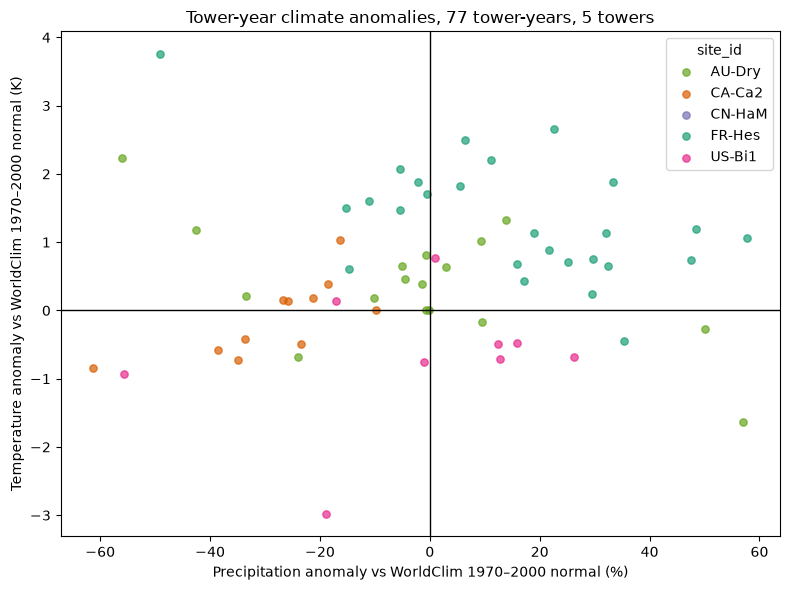

In [5]:
colors = dict(zip(sites["site_id"],
                  ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e"]))
fig, ax = plt.subplots(figsize=(8, 6))
for site, g in df.groupby("site_id"):
    ax.scatter(g["dP_pct"], g["dT"], s=28, alpha=0.7, color=colors[site], label=site)
ax.axhline(0, color="black", lw=1)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Precipitation anomaly vs WorldClim 1970–2000 normal (%)")
ax.set_ylabel("Temperature anomaly vs WorldClim 1970–2000 normal (K)")
ax.set_title(f"Tower-year climate anomalies, {n_years} tower-years, 5 towers")
ax.legend(title="site_id")
fig.tight_layout()
fig.savefig(FIG_DIR / "block5_fig1_anomaly_scatter.png", dpi=150)
plt.show()

## 5. Figure 2 — the two datasets at the five towers

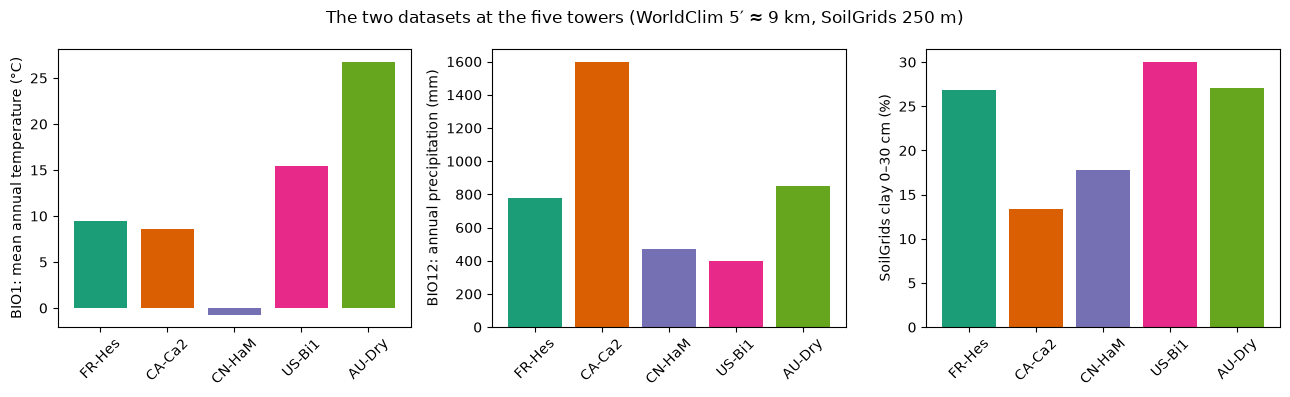

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
desc = static.set_index("site_id").loc[sites["site_id"]]
axes[0].bar(desc.index, desc["BIO1"], color=[colors[s] for s in desc.index])
axes[0].set_ylabel("BIO1: mean annual temperature (°C)")
axes[1].bar(desc.index, desc["BIO12"], color=[colors[s] for s in desc.index])
axes[1].set_ylabel("BIO12: annual precipitation (mm)")
axes[2].bar(desc.index, desc["soil0_30_clay"], color=[colors[s] for s in desc.index])
axes[2].set_ylabel("SoilGrids clay 0–30 cm (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("The two datasets at the five towers (WorldClim 5′ ≈ 9 km, SoilGrids 250 m)")
fig.tight_layout()
fig.savefig(FIG_DIR / "block5_fig2_site_description.png", dpi=150)
plt.show()

## 6. Second angle — does soil texture explain the precipitation anomaly?

With n = 4 towers (CN-HaM excluded) this is descriptive, not a test.

In [7]:
site_anom = df.groupby("site_id")[["dP_pct", "dT"]].mean()
site_anom = site_anom.join(static.set_index("site_id")[["soil0_30_clay", "soil0_30_sand"]])
site_anom_p = site_anom.dropna(subset=["dP_pct"])  # CN-HaM has no usable precipitation
print(f"r(dP_pct, clay) = {site_anom_p['dP_pct'].corr(site_anom_p['soil0_30_clay']):+.2f} (n={len(site_anom_p)} towers)")
print(f"r(dP_pct, sand) = {site_anom_p['dP_pct'].corr(site_anom_p['soil0_30_sand']):+.2f}")
site_anom.round(2)

r(dP_pct, clay) = +0.82 (n=4 towers)
r(dP_pct, sand) = -0.23


,dP_pct,dT,soil0_30_clay,soil0_30_sand
site_id,,,,
AU-Dry,-2.11,0.37,27.08,63.97
CA-Ca2,-28.22,-0.11,13.38,37.43
CN-HaM,NaN,-0.32,17.78,43.30
FR-Hes,14.88,1.34,26.87,21.95
US-Bi1,-2.69,-0.68,29.98,11.07
